In [ ]:
# This manually installs flams[automl] library as it is not included in the default Colab environment.
!pip install "flaml[automl]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 337.7/337.7 kB 13.5 MB/s eta 0:00:00
  Attempting uninstall: xgboost
    Found existing installation: xgboost 3.1.3
    Uninstalling xgboost-3.1.3:
      Successfully uninstalled xgboost-3.1.3


In [ ]:
# This cell imports necessary dataset and libraries. Do not change it.
# Data source: Quinlan, R. (1993). Auto MPG [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5859H.
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd
from sklearn.model_selection import train_test_split
from flaml import AutoML
from sklearn.metrics import mean_absolute_error
from matplotlib import pyplot as plt

# fetch dataset
auto_mpg = fetch_ucirepo(id=9)

# data (as pandas dataframes)
X = auto_mpg.data.features
y = auto_mpg.data.targets

In [ ]:
# Data cleaning
# This dataset is already split into X and y. Only X has NaN.
# Drop NaN from both X and corresponding y
df = pd.concat([X, y], axis=1) # This makes the combined dataframe along the columns (axis=1).
df_clean = df.dropna()  # Drop those rows.
X_clean = df_clean.drop(columns=['mpg'])  # Drop the target column.
y_clean = df_clean['mpg']  # Keep only the target column.

In [ ]:
# Split the data into training and test sets.
x_train, x_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.3, random_state=42)

In [ ]:
# Write the code to select the AutoML and specify its settings.
model = AutoML(seed=42,
               time_budget=60, # in seconds
               metric="mae",
               task="regression",
               n_splits=5
               )

In [ ]:
# Write the code to train the model with the training data.
model.fit(x_train, y_train)

[flaml.automl.logger: 02-16 07:12:33] {2375} INFO - task = regression
[flaml.automl.logger: 02-16 07:12:33] {2386} INFO - Evaluation method: cv
[flaml.automl.logger: 02-16 07:12:33] {2489} INFO - Minimizing error metric: mae
[flaml.automl.logger: 02-16 07:12:33] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd']
[flaml.automl.logger: 02-16 07:12:33] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 02-16 07:12:33] {3046} INFO - Estimated sufficient time budget=562s. Estimated necessary time budget=4s.
[flaml.automl.logger: 02-16 07:12:33] {3097} INFO -  at 0.1s,	estimator lgbm's best error=4.9569e+00,	best estimator lgbm's best error=4.9569e+00
[flaml.automl.logger: 02-16 07:12:33] {2911} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 02-16 07:12:33] {3097} INFO -  at 0.1s,	estimator lgbm's best error=4.9569e+00,	best estimator lgbm's best error=4.9569e+00
[flaml.automl.logger: 02-16 07:1

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 02-16 07:12:33] {3097} INFO -  at 0.3s,	estimator sgd's best error=6.7281e+00,	best estimator lgbm's best error=3.2063e+00
[flaml.automl.logger: 02-16 07:12:33] {2911} INFO - iteration 4, current learner lgbm
[flaml.automl.logger: 02-16 07:12:34] {3097} INFO -  at 0.4s,	estimator lgbm's best error=2.5124e+00,	best estimator lgbm's best error=2.5124e+00
[flaml.automl.logger: 02-16 07:12:34] {2911} INFO - iteration 5, current learner lgbm
[flaml.automl.logger: 02-16 07:12:34] {3097} INFO -  at 0.4s,	estimator lgbm's best error=2.5124e+00,	best estimator lgbm's best error=2.5124e+00
[flaml.automl.logger: 02-16 07:12:34] {2911} INFO - iteration 6, current learner lgbm
[flaml.automl.logger: 02-16 07:12:34] {3097} INFO -  at 0.5s,	estimator lgbm's best error=2.5124e+00,	best estimator lgbm's best error=2.5124e+00
[flaml.automl.logger: 02-16 07:12:34] {2911} INFO - iteration 7, current learner xgboost
[flaml.automl.logger: 02-16 07:12:34] {3097} INFO -  at 0.6s,	estimato

In [ ]:
# Write the code to make predictions with the test data.
y_predict = model.predict(x_test)

In [ ]:
# Write the code to calculate MAE, using the test data and the predctions.
mean_absolute_error(y_test,y_predict)

1.8705051584126149

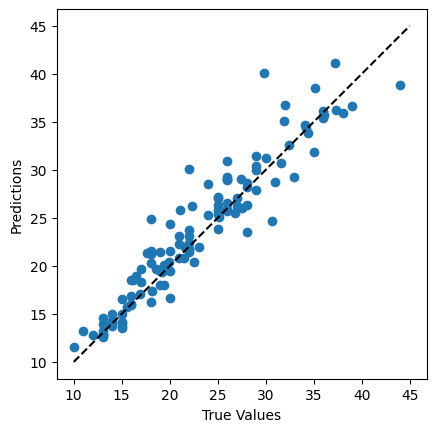

In [ ]:
# Visualize the predictions and actual values using a scatter plot with a y=x line.
plt.scatter(y_test,y_predict)
plt.xlabel('True Values')
plt.gca().set_aspect('equal')
plt.ylabel('Predictions')
plt.plot([10, 45], [10, 45], 'k--', label='y=x') # (Optional) this is a reference line. k means black. -- means dashed.
plt.show()